# 07 — Explainable AI: SHAP & LIME

**Research question:** Which acoustic features drive speech emotion predictions, and how consistent are SHAP and LIME explanations across different machine learning models?

This notebook investigates the interpretability of machine learning models trained for speech emotion recognition on the RAVDESS dataset.

The analysis focuses on global and local feature contributions, class-specific explanations, and the agreement between SHAP and LIME.

Unlike the previous notebooks, the objective is not to optimize predictive performance, but to understand and compare the decision-making behavior of existing classifiers.

All experiments will follow the established speaker-independent data splitting protocol to ensure consistency with the previous project stages.

In [ ]:

from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

SEED = 42

PROJECT_DIR = Path(
    '/content/drive/MyDrive/speech-emotion-recognition-project-d'
)

FEATURES_PATH = PROJECT_DIR / 'data/processed/ravdess_features.csv'

print("Project directory exists:", PROJECT_DIR.exists())
print("Features file exists:", FEATURES_PATH.exists())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory exists: True
Features file exists: True


## 2. Data Loading and Inspection

In [ ]:

import pandas as pd

df = pd.read_csv(FEATURES_PATH)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (1440, 49)


,relative_path,emotion,emotion_id,actor_id,gender,intensity,statement,repetition,duration_sec,sample_rate,...,zcr_std,spectral_centroid_mean,spectral_centroid_std,spectral_bandwidth_mean,spectral_bandwidth_std,spectral_rolloff_mean,spectral_rolloff_std,f0_hz_mean,f0_hz_std,voiced_ratio
0,Actor_01/03-01-01-01-01-01-01.wav,neutral,1,1,male,1,1,1,3.303292,48000,...,0.081081,1476.530023,815.358421,1451.287504,420.731907,2728.268678,1512.247496,116.565329,16.295102,0.931818
1,Actor_01/03-01-01-01-01-02-01.wav,neutral,1,1,male,1,1,2,3.336667,48000,...,0.078682,1481.953157,815.397130,1465.496831,368.994360,2799.030172,1358.868466,119.982938,18.750951,0.954545
2,Actor_01/03-01-01-01-02-01-01.wav,neutral,1,1,male,1,2,1,3.269917,48000,...,0.136101,1552.170971,1069.680859,1409.280748,388.172357,2795.955882,1578.248490,117.189317,14.108447,0.860465
3,Actor_01/03-01-01-01-02-02-01.wav,neutral,1,1,male,1,2,2,3.169833,48000,...,0.131457,1579.491982,1077.171054,1456.215793,420.858857,2866.705247,1651.301947,115.126709,14.849055,1.000000
4,Actor_01/03-01-02-01-01-01-01.wav,calm,2,1,male,1,1,1,3.536854,48000,...,0.137781,1586.385402,1095.428716,1461.860007,431.374998,2818.416262,1730.894205,116.941045,17.056856,0.596154


## 3. Feature Selection and Data Splitting

In [ ]:

# Acoustic features used in the original experiments
MFCC = [f'mfcc_{i:02d}_{s}' for i in range(1, 14)
        for s in ('mean', 'std')]

OTHER = [f'{name}_{s}'
         for name in ('rms', 'zcr', 'spectral_centroid',
                      'spectral_bandwidth', 'spectral_rolloff')
         for s in ('mean', 'std')]

FEATURE_COLS = MFCC + OTHER + [
    'f0_hz_mean', 'f0_hz_std', 'voiced_ratio'
]

# Speaker-independent split
train_mask = df['actor_id'].between(1, 12)
val_mask = df['actor_id'].between(13, 18)
test_mask = df['actor_id'].between(19, 24)

X_train = df.loc[train_mask, FEATURE_COLS]
y_train = df.loc[train_mask, 'emotion']

X_val = df.loc[val_mask, FEATURE_COLS]
y_val = df.loc[val_mask, 'emotion']

print("Features:", len(FEATURE_COLS))
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test recordings (reserved):", test_mask.sum())


Features: 39
Train: (720, 39)
Validation: (360, 39)
Test recordings (reserved): 360


**Пояснення:**

На цьому етапі ми визначаємо 39 акустичних ознак, які використовуватимуться для аналізу моделей. Вони включають MFCC (мел-частотні кепстральні коефіцієнти), характеристики енергії та частотного спектра голосу, а також основної частоти тону.

Далі розділяємо датасет за акторами, використовуючи той самий поділ, що й у попередніх експериментах:

- **Train (720 записів)** — актори 1–12, використовуються для навчання моделей.
- **Validation (360 записів)** — актори 13–18, використовуються для аналізу передбачень і пояснень.
- **Test (360 записів)** — актори 19–24, залишаються зарезервованими.

Такий поділ дозволяє перевіряти поведінку моделей на голосах людей, яких вони не бачили під час навчання.

## 4. Model Training for Explainability

In [ ]:

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, f1_score

SEED = 42

model = ExtraTreesClassifier(
    n_estimators=200,
    min_samples_leaf=4,
    random_state=SEED,
    n_jobs=-1
)

model.fit(X_train, y_train)

val_pred = model.predict(X_val)

print("Validation Accuracy:",
      round(accuracy_score(y_val, val_pred), 3))

print("Validation Macro F1:",
      round(f1_score(y_val, val_pred, average='macro'), 3))


Validation Accuracy: 0.414
Validation Macro F1: 0.391


ExtraTreesClassifier — ансамбль дерев рішень, які разом визначають емоцію.



n_estimators=200 — використовуємо 200 дерев.



min_samples_leaf=4 — обмежуємо складність дерев, щоб зменшити ризик перенавчання.



model.fit() — навчаємо модель на 720 записах.



model.predict() — передбачаємо емоції для 360 записів валідації.



Accuracy — частка правильних передбачень.



Macro F1 — середнє F1 для всіх восьми емоцій, де кожна емоція має однакову вагу.

**Пояснення:**

Для першого експерименту обрано модель Extra Trees — ансамблевий алгоритм, який використовує багато дерев рішень. Модель навчається на акустичних характеристиках голосу та намагається визначити одну з восьми емоцій.

Після навчання оцінюємо її якість на валідаційних даних за допомогою Accuracy та Macro F1. Отримані результати використовуватимуться як контекст для подальшого аналізу пояснень SHAP і LIME, а не для підбору параметрів моделі.

## 5. Hyperparameter Tuning — Extra Trees

In [ ]:

from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.ensemble import ExtraTreesClassifier

# Cross-validation with speaker-independent folds
cv = GroupKFold(n_splits=3)

param_grid = {
    'n_estimators': [200],
    'max_depth': [None, 10, 20],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 0.7]
}

grid = GridSearchCV(
    estimator=ExtraTreesClassifier(
        random_state=SEED,
        n_jobs=1
    ),
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid.fit(X_train, y_train, groups=df.loc[train_mask, 'actor_id'])

model = grid.best_estimator_

print("Best parameters:", grid.best_params_)
print("Best grouped CV Macro F1:", round(grid.best_score_, 3))


Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}
Best grouped CV Macro F1: 0.418


GridSearchCV — перевіряє різні комбінації параметрів.



GroupKFold — не дозволяє записам одного актора потрапити одночасно в навчальну та перевірочну частини одного fold.



max_depth — максимальна глибина дерев.



min_samples_leaf — мінімальна кількість записів у листку дерева.



max_features — скільки ознак розглядається під час пошуку розбиття.



n_estimators — кількість дерев.

**Пояснення:**

Початкова модель Extra Trees показала Validation Accuracy = 0.414 та Macro F1 = 0.391. Щоб перевірити можливість покращення якості, проводимо обмежений підбір гіперпараметрів за допомогою GridSearchCV.

Для оцінювання використовуємо GroupKFold із трьома розбиттями. Групування здійснюється за акторами, щоб записи однієї людини не потрапляли одночасно в навчальну та перевірочну вибірки.

Оптимальну конфігурацію обираємо за середнім Macro F1 на кросвалідації. Після цього модель буде зафіксована для подальшого аналізу SHAP і LIME.

In [ ]:

# Evaluate the tuned model on validation speakers
val_pred = model.predict(X_val)

val_accuracy = accuracy_score(y_val, val_pred)
val_macro_f1 = f1_score(y_val, val_pred, average='macro')

print("Tuned Extra Trees — Validation Accuracy:",
      round(val_accuracy, 3))

print("Tuned Extra Trees — Validation Macro F1:",
      round(val_macro_f1, 3))


Tuned Extra Trees — Validation Accuracy: 0.447
Tuned Extra Trees — Validation Macro F1: 0.434


**Пояснення:**

За результатами кросвалідації найкращою серед перевірених конфігурацій Extra Trees стала модель із 200 деревами без обмеження максимальної глибини та з мінімальною кількістю одного запису в листку.

Середній Macro F1 на GroupKFold становив 0.418. Тепер оцінюємо цю конфігурацію на окремій валідаційній вибірці, що містить записи акторів, які не використовувалися під час навчання.

Це дозволить порівняти якість початкової та налаштованої моделей на однакових даних.

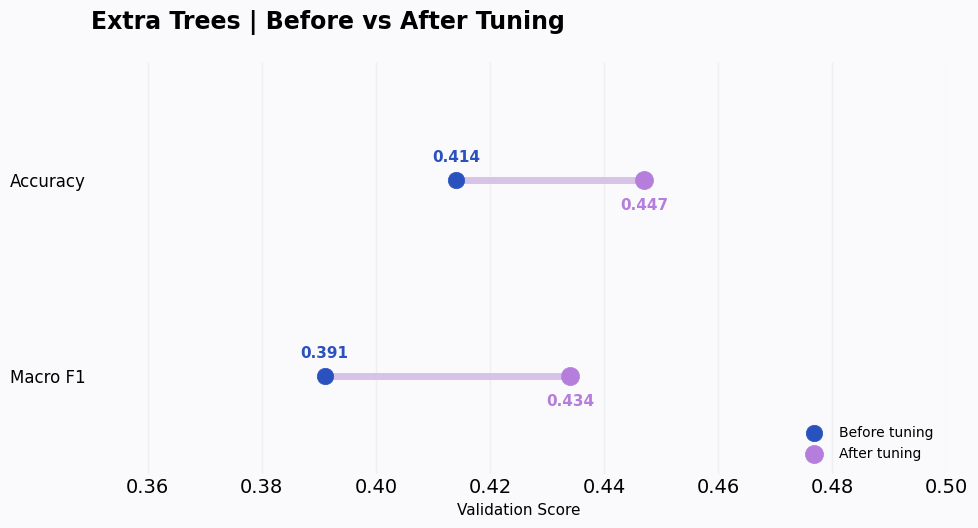

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Validation results
metrics = ['Accuracy', 'Macro F1']
before = np.array([0.414, 0.391])
after = np.array([0.447, 0.434])

# ThirtyFiveEight / FiveThirtyEight-inspired style
plt.style.use('fivethirtyeight')

BLUE = '#2A52BE'
PURPLE = '#B57EDC'

fig, ax = plt.subplots(figsize=(10, 5.5))
fig.patch.set_facecolor('#FAF9FC')
ax.set_facecolor('#FAF9FC')

y = np.arange(len(metrics))

# Connecting lines
for i in range(len(metrics)):
    ax.plot(
        [before[i], after[i]], [y[i], y[i]],
        color='#D7C3E7', linewidth=5,
        solid_capstyle='round', zorder=2
    )

# Before / after points
ax.scatter(before, y, s=140, color=BLUE,
           label='Before tuning', zorder=3)

ax.scatter(after, y, s=170, color=PURPLE,
           label='After tuning', zorder=4)

# Value labels
for i in range(len(metrics)):
    ax.annotate(f'{before[i]:.3f}',
                (before[i], y[i]),
                xytext=(0, 13),
                textcoords='offset points',
                ha='center', color=BLUE,
                fontsize=11, fontweight='bold')

    ax.annotate(f'{after[i]:.3f}',
                (after[i], y[i]),
                xytext=(0, -22),
                textcoords='offset points',
                ha='center', color=PURPLE,
                fontsize=11, fontweight='bold')

ax.set_yticks(y)
ax.set_yticklabels(metrics, fontsize=12)
ax.invert_yaxis()

ax.set_xlim(0.35, 0.50)
ax.set_ylim(1.5, -0.6)
ax.set_xlabel('Validation Score', fontsize=11)

ax.set_title(
    'Extra Trees | Before vs After Tuning',
    fontsize=17, fontweight='bold',
    loc='left', pad=24
)

ax.grid(axis='x', alpha=0.22)
ax.grid(axis='y', visible=False)

ax.legend(loc='lower right', frameon=False,
          fontsize=10)

sns.despine(left=True, bottom=True)
plt.tight_layout()

# Save figure
FIGURES_DIR = PROJECT_DIR / 'results/07_xai/figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURES_DIR / 'extra_trees_tuning_comparison.png',
    dpi=200, bbox_inches='tight'
)

plt.show()


## 6. Frozen Model for Explainability

In [ ]:

import joblib

# Save the tuned Extra Trees model
MODEL_DIR = PROJECT_DIR / 'results/07_xai'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / 'extra_trees_xai.joblib'

joblib.dump(model, MODEL_PATH)

print("Model saved to:", MODEL_PATH)
print("Model classes:", model.classes_)


Model saved to: /content/drive/MyDrive/speech-emotion-recognition-project-d/results/07_xai/extra_trees_xai.joblib
Model classes: ['angry' 'calm' 'disgust' 'fearful' 'happy' 'neutral' 'sad' 'surprised']


ODEL_DIR — папка, у якій зберігатимемо результати нашої частини проєкту.



mkdir() — створює папку, якщо її ще немає.



joblib.dump() — зберігає вже навчену модель у файл.



model.classes_ — показує порядок емоцій, який використовує модель. Це особливо важливо для багатокласового SHAP

На даний момет є:
У нас зараз:
1. Навчили Extra Trees → Macro F1 = 0.391.
2. Підібрали гіперпараметри через GroupKFold.
3. Отримали Macro F1 = 0.434 на validation.
4. Тепер фіксуємо модель, щоб досліджувати її рішення.

## 7. SHAP Explainability Analysis

### 7.1. SHAP Initialization

**Пояснення:**

SHAP (SHapley Additive exPlanations) — метод пояснення передбачень моделей машинного навчання, заснований на значеннях Шеплі з теорії ігор.

SHAP оцінює внесок кожної ознаки у передбачення моделі відносно базового значення. Це дозволяє досліджувати як загальну важливість акустичних характеристик, так і причини окремих передбачень емоцій.

Для аналізу Extra Trees використовуємо TreeExplainer, призначений для деревних моделей.

In [ ]:

import shap
import numpy as np

# Initialize SHAP explainer for Extra Trees
explainer = shap.TreeExplainer(model)

print("SHAP version:", shap.__version__)
print("Explainer:", type(explainer).__name__)
print("Number of classes:", len(model.classes_))
print("Classes:", model.classes_)


SHAP version: 0.54.1
Explainer: TreeExplainer
Number of classes: 8
Classes: ['angry' 'calm' 'disgust' 'fearful' 'happy' 'neutral' 'sad' 'surprised']


Що тут відбувається?
- import shap — підключаємо бібліотеку для пояснення моделей.
- shap.TreeExplainer(model) — створюємо об'єкт, який зможе обчислювати внесок кожної акустичної ознаки в передбачення Extra Trees.
- model.classes_ — перевіряємо назви та порядок емоцій, адже у нас багатокласова класифікація.

### 7.2. SHAP Value Computation

In [ ]:

# Select validation samples for SHAP analysis
X_shap = X_val.sample(n=100, random_state=SEED)

# Compute SHAP values
shap_values = explainer(X_shap)

print("SHAP values shape:", shap_values.values.shape)
print("Base values shape:", shap_values.base_values.shape)
print("Number of features:", X_shap.shape[1])
print("Number of classes:", len(model.classes_))


SHAP values shape: (100, 39, 8)
Base values shape: (100, 8)
Number of features: 39
Number of classes: 8


Що тут відбувається?
1. X_val.sample(n=100)

Ми випадково обираємо 100 записів із валідаційної вибірки.

Чому не всі 360? Для першого аналізу 100 достатньо, щоб перевірити обчислення та побудувати графіки без зайвого навантаження. Пізніше зможемо використати всю вибірку.

2. explainer(X_shap)

SHAP обчислює внесок кожної з 39 акустичних ознак у передбачення моделі для кожного запису та кожної емоції.

3. shap_values.values.shape

Очікуємо:

(100, 39, 8)

Це означає:
- 100 — аудіозаписів.
- 39 — акустичних ознак.
- 8 — класів емоцій.
4. shap_values.base_values

Базові значення, від яких SHAP пояснює передбачення кожного класу.

Для нашої Extra Trees із типовими налаштуваннями TreeExplainer пояснює ймовірності класів. Тобто внески SHAP показують, як ознаки збільшують або зменшують передбачену ймовірність конкретної емоції відносно базового значення.

### 7.3. Local Explanation — SHAP Waterfall Plot

Predicted emotion: disgust
Predicted probability: 0.52
True emotion: disgust


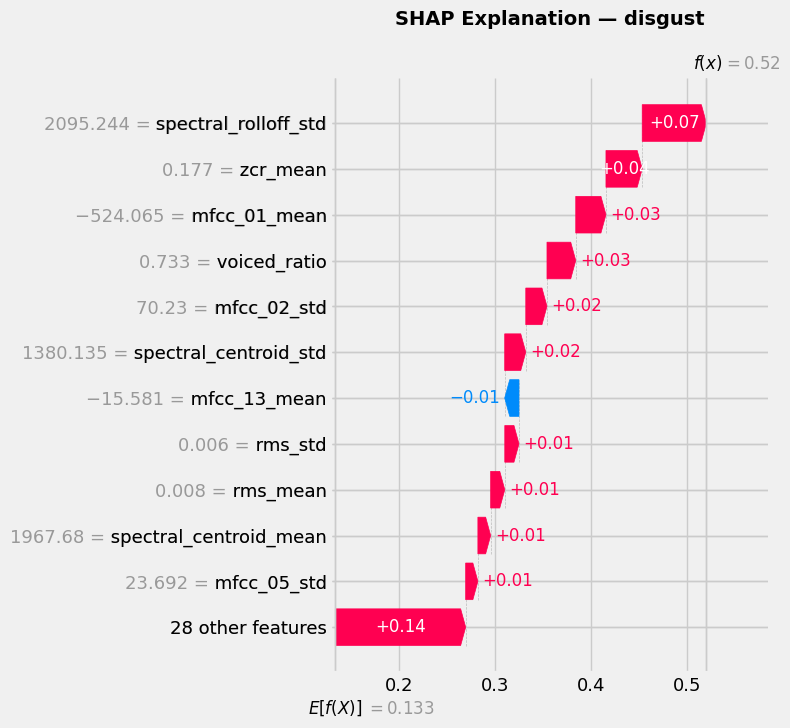

In [ ]:

import matplotlib.pyplot as plt

# Select one validation recording
sample_idx = 0

# Get model prediction for this recording
sample = X_shap.iloc[[sample_idx]]
predicted_emotion = model.predict(sample)[0]
predicted_probability = model.predict_proba(sample)[0].max()

# Find the predicted class index
class_idx = list(model.classes_).index(predicted_emotion)

print("Predicted emotion:", predicted_emotion)
print("Predicted probability:", round(predicted_probability, 3))
print("True emotion:", y_val.loc[sample.index[0]])

# Explain the predicted class
shap.plots.waterfall(
    shap_values[sample_idx, :, class_idx],
    max_display=12,
    show=False
)

plt.title(
    f"SHAP Explanation — {predicted_emotion}",
    fontsize=14,
    fontweight='bold',
    pad=20
)

plt.tight_layout()
plt.show()


Модель правильно визначила емоцію disgust із ймовірністю 52%.

А SHAP відповідає на питання: чому модель дала саме 52%, а не, наприклад, 13%?
- Червоні смужки — характеристики голосу, які підвищили ймовірність disgust.
- Сині — характеристики, які її знизили.
- Усі внески разом перетворили базову ймовірність приблизно 13% на 52%.

### 7.4. Global SHAP Feature Importance

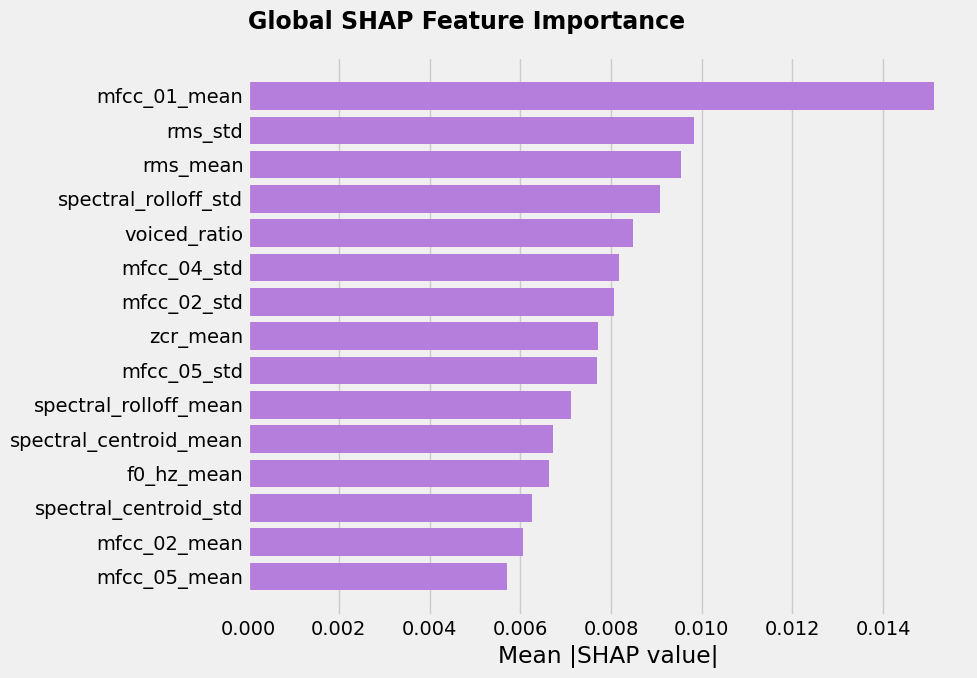

,Feature,Mean Absolute SHAP
0,mfcc_01_mean,0.015116
27,rms_std,0.009832
26,rms_mean,0.009546
35,spectral_rolloff_std,0.009088
38,voiced_ratio,0.008481
7,mfcc_04_std,0.008170
3,mfcc_02_std,0.008066
28,zcr_mean,0.007707
9,mfcc_05_std,0.007681
34,spectral_rolloff_mean,0.007118


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Mean absolute SHAP value across samples and classes
global_importance = np.abs(shap_values.values).mean(axis=(0, 2))

importance_df = pd.DataFrame({
    'Feature': X_shap.columns,
    'Mean Absolute SHAP': global_importance
}).sort_values('Mean Absolute SHAP', ascending=False)

# Display top 15 features
top_features = importance_df.head(15)

plt.style.use('fivethirtyeight')

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top_features['Feature'][::-1],
    top_features['Mean Absolute SHAP'][::-1],
    color='#B57EDC'
)

ax.set_title(
    'Global SHAP Feature Importance',
    fontsize=17,
    fontweight='bold',
    loc='left',
    pad=20
)

ax.set_xlabel('Mean |SHAP value|')
ax.set_ylabel('')
ax.grid(axis='y', visible=False)

plt.tight_layout()
plt.show()

display(importance_df.head(15))


**Пояснення:**

Для оцінювання глобальної важливості акустичних ознак обчислюємо середні абсолютні SHAP-значення за 100 валідаційними записами та вісьмома класами емоцій.

Абсолютне значення дозволяє враховувати силу внеску ознаки незалежно від того, збільшує вона чи зменшує ймовірність певної емоції.

На графіку відображено 15 ознак із найбільшим середнім абсолютним внеском. Це допомагає визначити, які характеристики голосу найбільше впливають на передбачення моделі Extra Trees у досліджуваній вибірці.

### 7.5. SHAP Beeswarm Plot — Class-Specific Explanation

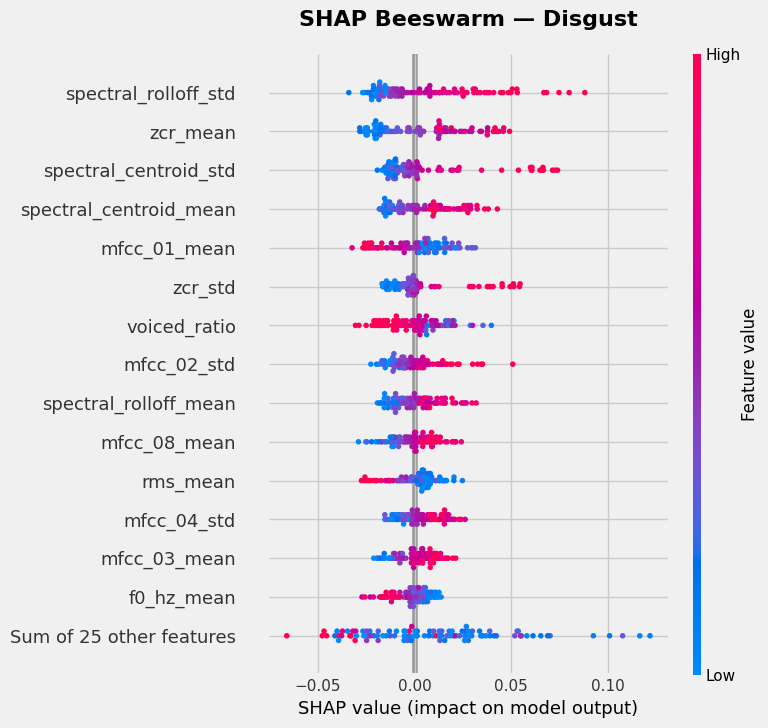

In [ ]:

# Select emotion to explain
target_emotion = 'disgust'
class_idx = list(model.classes_).index(target_emotion)

# SHAP values for the selected emotion
class_shap_values = shap_values[:, :, class_idx]

plt.figure(figsize=(11, 8))

shap.plots.beeswarm(
    class_shap_values,
    max_display=15,
    show=False
)

plt.title(
    f'SHAP Beeswarm — {target_emotion.capitalize()}',
    fontsize=16,
    fontweight='bold',
    pad=20
)

plt.tight_layout()
plt.show()


**Пояснення:**

Для детальнішого аналізу обираємо клас `disgust` і будуємо SHAP Beeswarm Plot на основі 100 валідаційних записів.

Кожна точка відповідає окремому аудіозапису. Її положення на горизонтальній осі відображає SHAP-внесок ознаки у прогнозовану ймовірність емоції `disgust`, а колір показує величину значення цієї ознаки.

Графік дозволяє дослідити, як різні значення акустичних характеристик пов'язані зі збільшенням або зменшенням прогнозованої ймовірності конкретної емоції.

### 7.6. SHAP Feature Importance Across Emotions

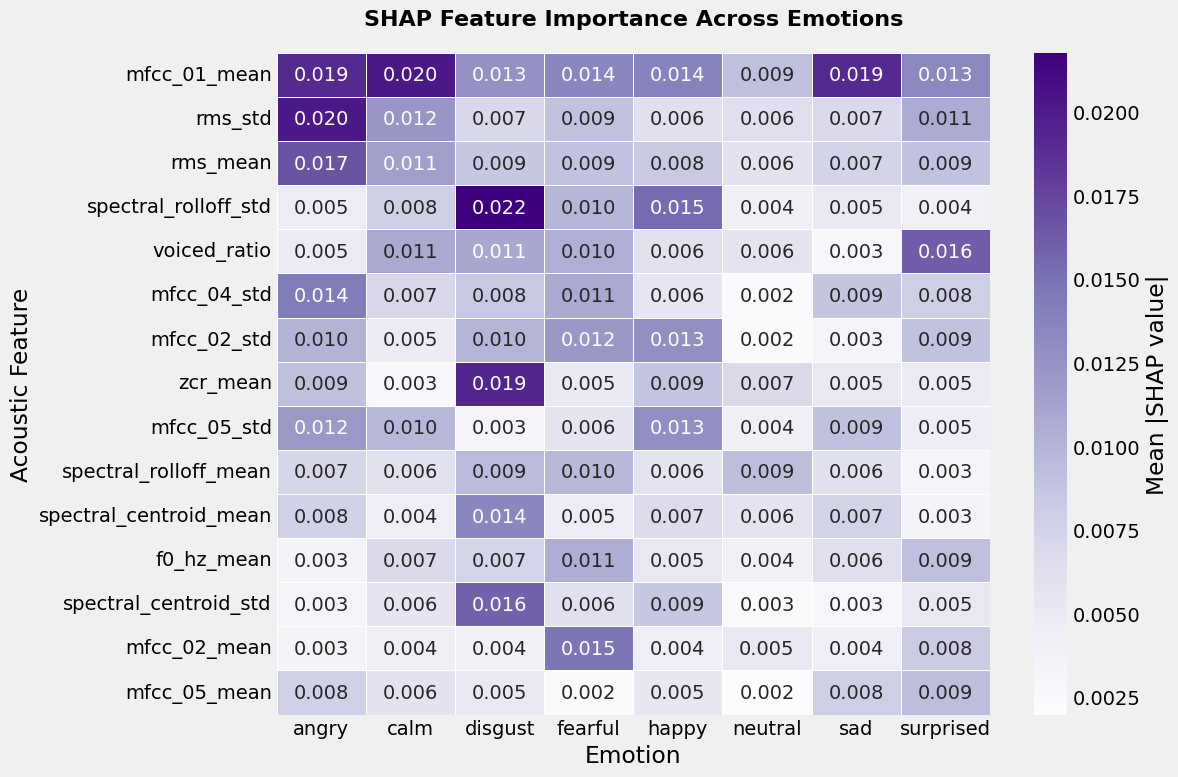

In [ ]:

import seaborn as sns

# Mean absolute SHAP values for each feature and emotion
class_importance = np.abs(shap_values.values).mean(axis=0)

# Create feature × emotion DataFrame
class_importance_df = pd.DataFrame(
    class_importance,
    index=X_shap.columns,
    columns=model.classes_
)

# Select top 15 globally important features
top_feature_names = importance_df.head(15)['Feature']

heatmap_data = class_importance_df.loc[top_feature_names]

plt.style.use('fivethirtyeight')

fig, ax = plt.subplots(figsize=(12, 8))

sns.heatmap(
    heatmap_data,
    cmap='Purples',
    annot=True,
    fmt='.3f',
    linewidths=0.5,
    cbar_kws={'label': 'Mean |SHAP value|'},
    ax=ax
)

ax.set_title(
    'SHAP Feature Importance Across Emotions',
    fontsize=16,
    fontweight='bold',
    pad=20
)

ax.set_xlabel('Emotion')
ax.set_ylabel('Acoustic Feature')

plt.tight_layout()
plt.show()


**Пояснення:**

Для порівняння пояснень між вісьмома класами емоцій обчислюємо середні абсолютні SHAP-значення кожної акустичної ознаки окремо для кожного класу.

Результати візуалізуємо у вигляді теплової карти для 15 ознак із найбільшою глобальною важливістю.

Інтенсивність кольору відображає середню силу впливу ознаки на прогнозовану ймовірність відповідної емоції. Це дозволяє дослідити, які характеристики голосу модель використовує найбільш активно для розрізнення окремих емоцій.

## 8. LIME Explainability Analysis

### 8.1. LIME Initialization

In [ ]:

%pip -q install lime


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:

from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(),
    feature_names=FEATURE_COLS,
    class_names=list(model.classes_),
    mode='classification',
    discretize_continuous=True,
    random_state=SEED
)

print("LIME explainer initialized successfully!")
print("Number of features:", len(FEATURE_COLS))
print("Classes:", model.classes_)


LIME explainer initialized successfully!
Number of features: 39
Classes: ['angry' 'calm' 'disgust' 'fearful' 'happy' 'neutral' 'sad' 'surprised']


Що тут відбувається?
- LimeTabularExplainer — створюємо LIME для табличних даних, адже наші аудіозаписи вже представлені 39 числовими ознаками.
- training_data=X_train.to_numpy() — LIME використовує тренувальні дані, щоб оцінити розподіл ознак і генерувати змінені приклади.
- feature_names — передаємо назви акустичних характеристик.
- class_names — задаємо назви восьми емоцій у тому самому порядку, що й у моделі.
- discretize_continuous=True — LIME розбиває числові ознаки на інтервали, щоб пояснення були зрозумілішими.
- random_state=SEED — фіксуємо випадковість для відтворюваності.

**Пояснення:**

LIME — метод локального пояснення передбачень моделей машинного навчання. На відміну від SHAP, він наближує поведінку складної моделі простою інтерпретованою моделлю в околі конкретного спостереження.

Для аналізу використовуємо LimeTabularExplainer, оскільки кожен аудіозапис представлений набором із 39 числових акустичних ознак.

Для створення локальних пояснень LIME використовуватиме розподіли ознак тренувальної вибірки, не змінюючи параметрів уже навченої моделі Extra Trees.

### 8.2. Local Explanation — LIME

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but ExtraTreesClassifier was fitted with feature names
  warnings.warn(


Predicted emotion: disgust
True emotion: disgust
Predicted probability: 0.52


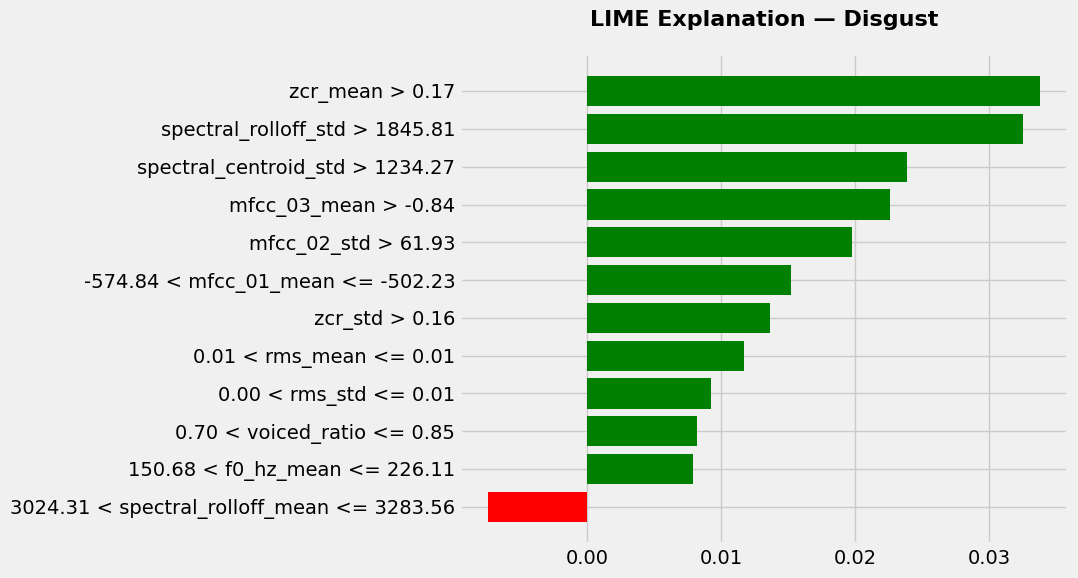

In [ ]:

# Use the same recording as in SHAP Waterfall
sample_idx = 0
sample = X_shap.iloc[[sample_idx]]

# Get predicted emotion and its class index
predicted_emotion = model.predict(sample)[0]
class_idx = list(model.classes_).index(predicted_emotion)

# Generate LIME explanation
lime_exp = lime_explainer.explain_instance(
    data_row=sample.iloc[0].to_numpy(),
    predict_fn=model.predict_proba,
    labels=[class_idx],
    num_features=12,
    num_samples=5000
)

print("Predicted emotion:", predicted_emotion)
print("True emotion:", y_val.loc[sample.index[0]])
print("Predicted probability:",
      round(model.predict_proba(sample)[0, class_idx], 3))

# Plot local explanation
fig = lime_exp.as_pyplot_figure(label=class_idx)
fig.set_size_inches(11, 6)

plt.title(
    f'LIME Explanation — {predicted_emotion.capitalize()}',
    fontsize=16,
    fontweight='bold',
    pad=20
)

plt.tight_layout()
plt.show()


Що відбувається?
1. sample_idx = 0 — беремо той самий запис, для якого SHAP показав disgust із ймовірністю 0.52.
2. model.predict_proba — передаємо LIME функцію, яка повертає ймовірності всіх восьми емоцій.
3. labels=[class_idx] — просимо пояснити саме передбачений клас disgust.
4. num_features=12 — відображаємо 12 найважливіших ознак у локальному поясненні.
5. num_samples=5000 — LIME створює 5000 штучно змінених прикладів, щоб наблизити поведінку моделі поблизу вибраного запису.

Як читати графік?
LIME покаже горизонтальні смужки з додатними та від'ємними вагами.

Додатна вага означає, що відповідна умова для ознаки підтримує передбачення disgust у локальній наближеній моделі. Від'ємна — діє проти нього.

На відміну від SHAP, ці ваги не є точним розкладом прогнозованої ймовірності Extra Trees. LIME лише приблизно відтворює її поведінку навколо вибраного запису.

**Пояснення:**

Для локального аналізу LIME обираємо той самий валідаційний аудіозапис, який раніше пояснювали методом SHAP. Модель правильно класифікувала його як `disgust` із прогнозованою ймовірністю 0.52.

LIME генерує 5000 змінених прикладів на основі характеристик вибраного запису та навчає локальну інтерпретовану модель для наближення передбачень Extra Trees.

На графіку відображаємо 12 ознак із найбільшими за модулем локальними вагами. Додатні ваги підтримують передбачення вибраної емоції, а від'ємні — протидіють йому.

Отримане пояснення надалі порівнюватимемо з SHAP Waterfall для того самого аудіозапису.

### 8.3. SHAP vs LIME — Local Feature Ranking

In [ ]:

# SHAP contributions for the selected recording and emotion
shap_local = pd.Series(
    shap_values.values[sample_idx, :, class_idx],
    index=FEATURE_COLS
)

# LIME contributions for the same recording and emotion
lime_local = pd.Series(
    dict(lime_exp.as_map()[class_idx])
)

# Convert LIME feature indices to names
lime_local.index = [FEATURE_COLS[i] for i in lime_local.index]

# Rank features by absolute contribution
shap_top = shap_local.abs().nlargest(10).index.tolist()
lime_top = lime_local.abs().nlargest(10).index.tolist()

comparison = pd.DataFrame({
    'SHAP Top 10': shap_top,
    'LIME Top 10': lime_top
})

display(comparison)

# Features appearing in both top-10 lists
common_features = set(shap_top) & set(lime_top)

print("Common features:", len(common_features))
print("Overlapping features:", sorted(common_features))


,SHAP Top 10,LIME Top 10
0,spectral_rolloff_std,zcr_mean
1,zcr_mean,spectral_rolloff_std
2,mfcc_01_mean,spectral_centroid_std
3,voiced_ratio,mfcc_03_mean
4,mfcc_02_std,mfcc_02_std
5,spectral_centroid_std,mfcc_01_mean
6,mfcc_13_mean,zcr_std
7,rms_std,rms_mean
8,rms_mean,rms_std
9,spectral_centroid_mean,voiced_ratio


Common features: 8
Overlapping features: ['mfcc_01_mean', 'mfcc_02_std', 'rms_mean', 'rms_std', 'spectral_centroid_std', 'spectral_rolloff_std', 'voiced_ratio', 'zcr_mean']


Що тут відбувається?
- shap_local — SHAP-внески всіх 39 ознак для конкретного запису.
- lime_local — LIME-ваги для 12 ознак, які ми попросили пояснити.
- .abs().nlargest(10) — вибираємо 10 ознак із найбільшим за модулем впливом.
- common_features — знаходимо ознаки, які потрапили до обох списків.

**Пояснення:**

Для порівняння локальних пояснень SHAP і LIME використовуємо один і той самий аудіозапис та передбачений клас `disgust`.

Оскільки методи обчислюють внески ознак по-різному, порівнюємо не абсолютні значення їхніх оцінок, а ранжування ознак за силою впливу.

Для кожного методу визначаємо 10 найважливіших акустичних характеристик і обчислюємо кількість спільних ознак. Це дозволяє оцінити узгодженість локальних пояснень двох методів для конкретного передбачення.

### 8.4. SHAP vs LIME — Visual Comparison

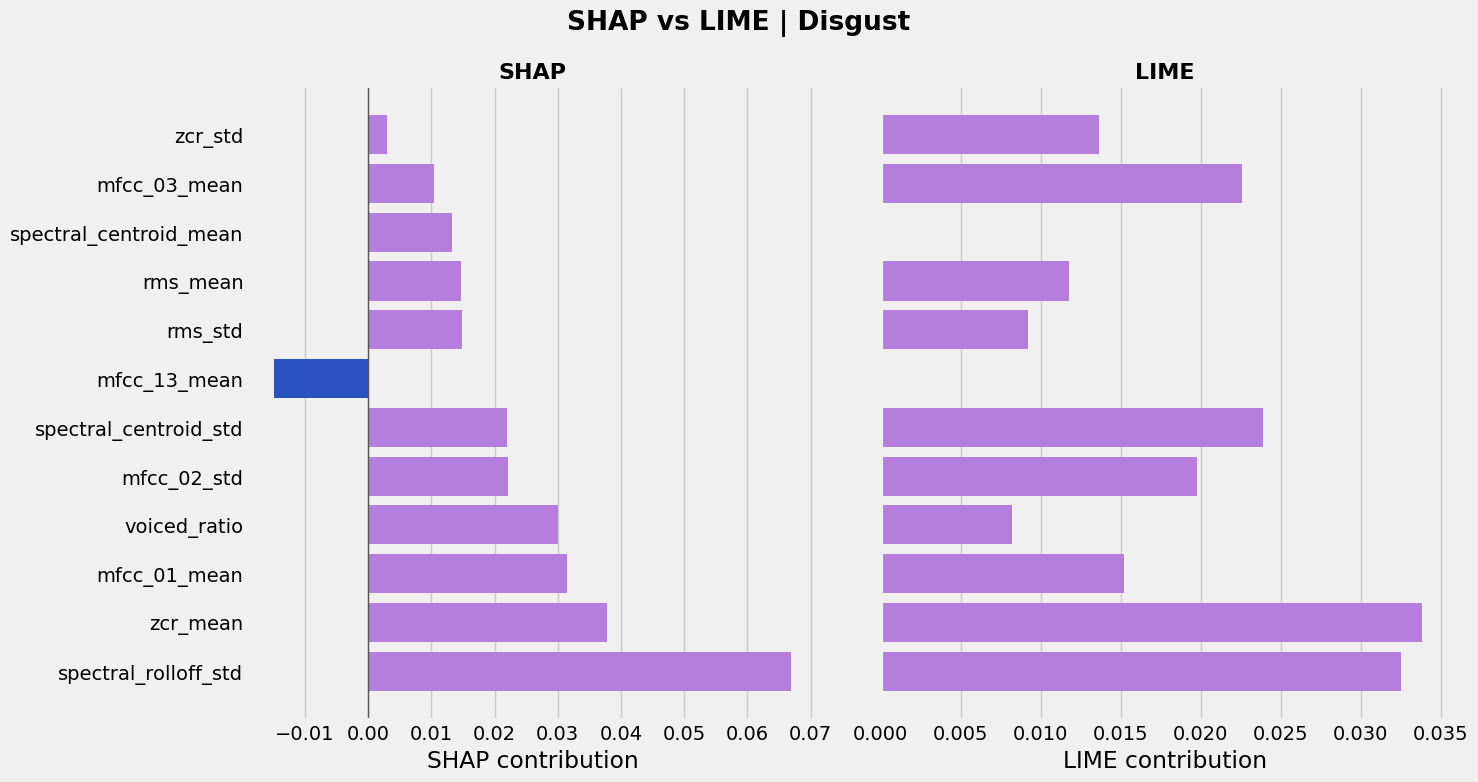

In [ ]:

# Compare local explanations for the same recording
top_n = 10

# Select features from the union of both top lists
features = list(dict.fromkeys(shap_top + lime_top))

# Build comparison table
plot_df = pd.DataFrame({
    'SHAP': shap_local.reindex(features).fillna(0),
    'LIME': lime_local.reindex(features).fillna(0)
})

# Separate axes because SHAP and LIME use different scales
plt.style.use('fivethirtyeight')

fig, axes = plt.subplots(
    1, 2, figsize=(15, 8),
    sharey=True
)

colors = {
    'positive': '#B57EDC',
    'negative': '#2A52BE'
}

for ax, method in zip(axes, ['SHAP', 'LIME']):
    values = plot_df[method]
    bar_colors = [
        colors['positive'] if v >= 0
        else colors['negative']
        for v in values
    ]

    ax.barh(
        values.index,
        values.values,
        color=bar_colors
    )

    ax.axvline(0, color='#555555', linewidth=1)
    ax.set_title(
        method,
        fontsize=16,
        fontweight='bold'
    )
    ax.set_xlabel(f'{method} contribution')
    ax.grid(axis='y', visible=False)
    ax.invert_yaxis()

fig.suptitle(
    f'SHAP vs LIME | {predicted_emotion.capitalize()}',
    fontsize=19,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


**Пояснення:**

Для візуального порівняння локальних пояснень SHAP і LIME будуємо два горизонтальні графіки для одного аудіозапису, правильно класифікованого як `disgust`.

Кольори відображають напрямок внеску ознак: додатний або від'ємний. Методи використовують різні способи обчислення пояснень, тому їхні числові значення не порівнюються безпосередньо.

У попередньому аналізі виявлено 8 спільних ознак серед десяти найважливіших для кожного методу. Це свідчить про значний перетин локальних пояснень для вибраного запису, але не гарантує такої самої узгодженості для інших аудіозаписів.

## 9. Error Analysis Using SHAP and LIME

### 9.1. Misclassified Recording Selection

In [ ]:

# Find incorrectly classified validation recordings
val_predictions = model.predict(X_val)

incorrect_mask = val_predictions != y_val.to_numpy()
incorrect_indices = np.where(incorrect_mask)[0]

print("Misclassified recordings:", len(incorrect_indices))
print("Total validation recordings:", len(X_val))

# Select the first misclassified recording
error_idx = incorrect_indices[0]

error_sample = X_val.iloc[[error_idx]]
true_emotion = y_val.iloc[error_idx]
predicted_emotion_error = val_predictions[error_idx]

print("\nTrue emotion:", true_emotion)
print("Predicted emotion:", predicted_emotion_error)

# Predicted probabilities for all emotions
error_proba = model.predict_proba(error_sample)[0]

display(pd.DataFrame({
    'Emotion': model.classes_,
    'Probability': error_proba
}).sort_values('Probability', ascending=False))


Misclassified recordings: 199
Total validation recordings: 360

True emotion: neutral
Predicted emotion: sad


,Emotion,Probability
6,sad,0.225
4,happy,0.215
5,neutral,0.195
1,calm,0.180
7,surprised,0.085
0,angry,0.040
3,fearful,0.035
2,disgust,0.025


**Пояснення:**

Для аналізу помилок класифікації визначаємо аудіозаписи з валідаційної вибірки, для яких передбачена моделлю емоція не збігається зі справжньою.

Обираємо один неправильно класифікований запис і досліджуємо розподіл прогнозованих ймовірностей між вісьмома класами.

Надалі використаємо SHAP і LIME, щоб пояснити, які акустичні характеристики підтримували неправильне передбачення моделі та як вони впливали на ймовірність справжньої емоції.

### 9.2. SHAP Explanation of a Misclassified Recording

True emotion: neutral
Predicted emotion: sad
Predicted class probability: 0.225
True class probability: 0.195


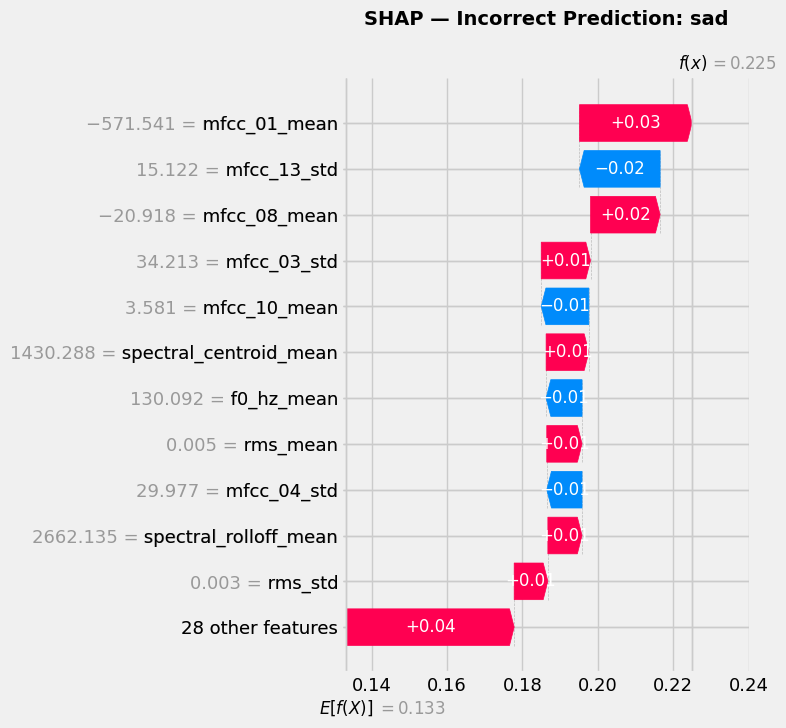

In [ ]:

# Explain the misclassified recording using SHAP
error_shap = explainer(error_sample)

# Get indices of predicted and true emotions
pred_idx = list(model.classes_).index(predicted_emotion_error)
true_idx = list(model.classes_).index(true_emotion)

print("True emotion:", true_emotion)
print("Predicted emotion:", predicted_emotion_error)

print("Predicted class probability:",
      round(error_proba[pred_idx], 3))

print("True class probability:",
      round(error_proba[true_idx], 3))

# SHAP explanation for the incorrect prediction
shap.plots.waterfall(
    error_shap[0, :, pred_idx],
    max_display=12,
    show=False
)

plt.title(
    f'SHAP — Incorrect Prediction: {predicted_emotion_error}',
    fontsize=14,
    fontweight='bold',
    pad=20
)

plt.tight_layout()
plt.show()


**Пояснення:**

Для неправильно класифікованого аудіозапису обчислюємо SHAP-значення та будуємо Waterfall Plot для емоції, яку передбачила модель.

Графік відображає внески акустичних ознак у прогнозовану ймовірність помилково обраного класу. Додатні внески підвищують цю ймовірність відносно базового значення, а від'ємні — знижують.

Також порівнюємо ймовірності передбаченої та справжньої емоцій, щоб оцінити, наскільки сильно модель віддала перевагу неправильному класу.

### 9.3. SHAP Explanation of the True Emotion

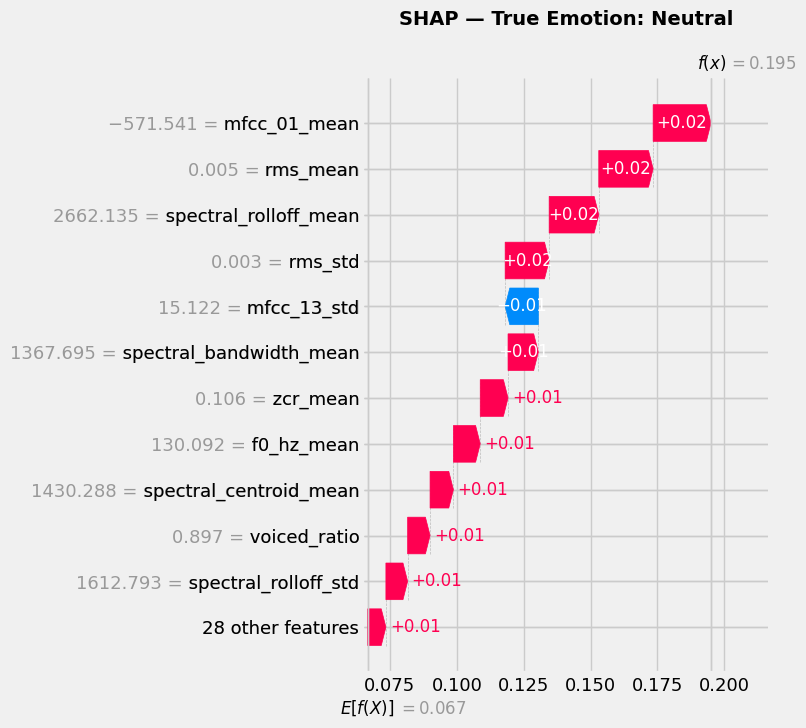

In [ ]:

# SHAP explanation for the true emotion
shap.plots.waterfall(
    error_shap[0, :, true_idx],
    max_display=12,
    show=False
)

plt.title(
    f'SHAP — True Emotion: {true_emotion.capitalize()}',
    fontsize=14,
    fontweight='bold',
    pad=20
)

plt.tight_layout()
plt.show()


**Пояснення:**

Для того самого неправильно класифікованого аудіозапису будуємо SHAP Waterfall Plot для справжнього класу емоції.

На відміну від попереднього графіка, який пояснював помилково передбачений клас, цей графік показує внески акустичних ознак у ймовірність правильної емоції.

Порівняння двох пояснень дозволяє дослідити, як ті самі характеристики голосу вплинули на ймовірності двох конкуруючих класів і чому модель віддала перевагу неправильному передбаченню.

## 10. Additional Explainability Experiments

### 10.1. SHAP Dependence Plot

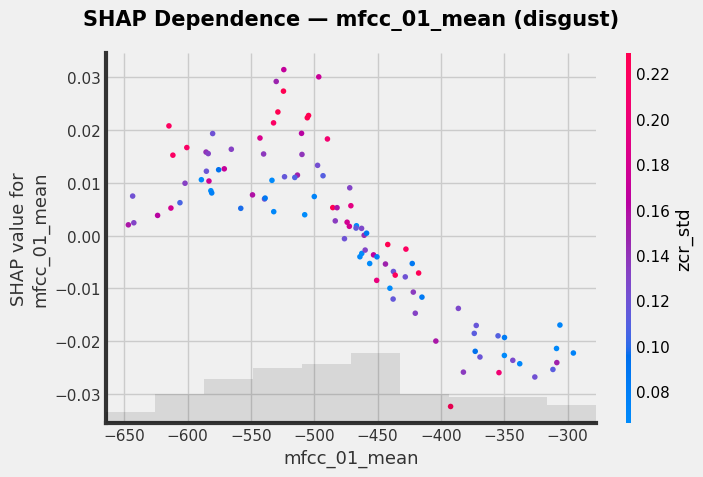

In [ ]:

import matplotlib.pyplot as plt
import shap

# Select emotion and acoustic feature
target_emotion = 'disgust'
feature_name = 'mfcc_01_mean'

class_idx = list(model.classes_).index(target_emotion)

# SHAP values for the selected emotion
class_shap_values = shap_values[:, :, class_idx]

plt.style.use('fivethirtyeight')

# Dependence scatter plot
shap.plots.scatter(
    class_shap_values[:, feature_name],
    color=class_shap_values,
    show=False
)

plt.title(
    f'SHAP Dependence — {feature_name} ({target_emotion})',
    fontsize=15,
    fontweight='bold',
    pad=20
)

plt.tight_layout()
plt.show()


Що тут відбувається?
- Вісь X — фактичне значення mfcc_01_mean для аудіозапису.
- Вісь Y — SHAP-внесок цієї ознаки в ймовірність disgust.
- Колір точок — значення іншої ознаки, яку SHAP автоматично обирає як можливу взаємодію.
Це вже цікавіше за звичайний рейтинг важливості, бо можна побачити, чи змінюється внесок ознаки зі зростанням її значення.

**Пояснення:**

Для детальнішого дослідження впливу акустичних характеристик будуємо SHAP Dependence Plot для ознаки `mfcc_01_mean` та класу `disgust`.

Горизонтальна вісь відображає фактичні значення ознаки, а вертикальна — її SHAP-внесок у прогнозовану ймовірність відповідної емоції.

Графік дозволяє дослідити залежність між величиною акустичної характеристики та її впливом на передбачення моделі. Колір точок може додатково відображати потенційну взаємодію з іншою ознакою.

Зверни увагу: коли mfcc_01_mean приблизно від −550 до −500, його SHAP-внесок для disgust переважно додатний. А коли значення наближається до −350, внесок стає від'ємним.

Тобто вища величина mfcc_01_mean у цій області пов'язана зі зменшенням прогнозованої ймовірності disgust. Але це поведінка нашої моделі, а не універсальна закономірність людського голосу.

І кольори тут відповідають zcr_std — SHAP автоматично вибрав цю ознаку для візуалізації можливої взаємодії.

### 10.2. SHAP Decision Plot

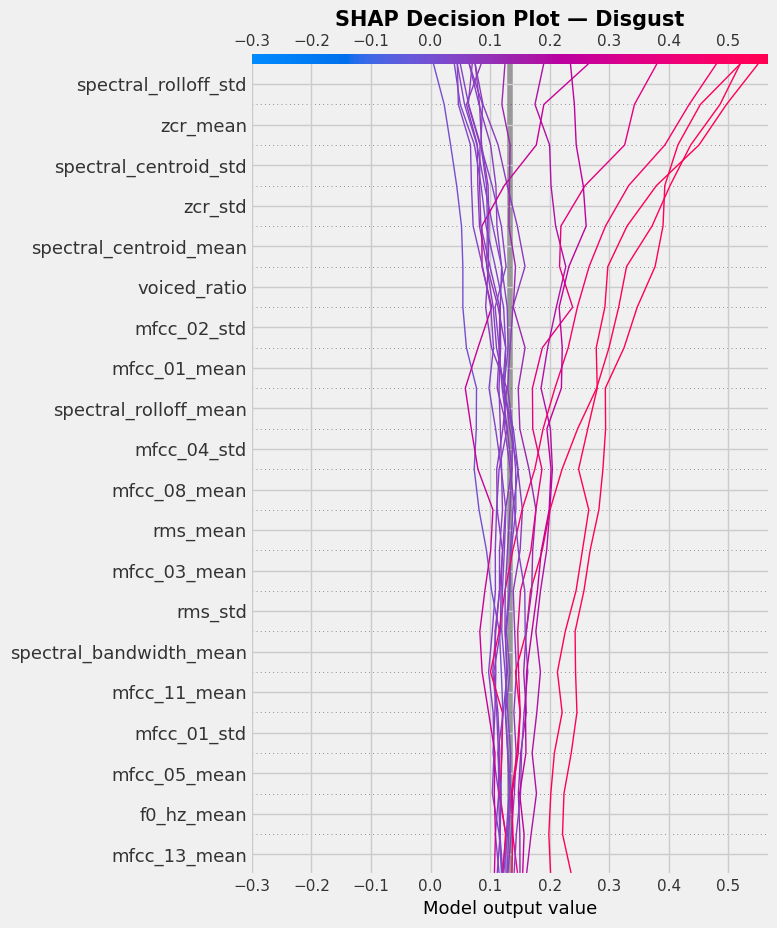

In [ ]:

# Select one emotion
target_emotion = 'disgust'
class_idx = list(model.classes_).index(target_emotion)

# Use 20 validation recordings
n_samples = 20

# SHAP values for selected emotion
decision_values = shap_values.values[
    :n_samples, :, class_idx
]

# Base value for the selected emotion
base_value = shap_values.base_values[0, class_idx]

plt.style.use('fivethirtyeight')

shap.decision_plot(
    base_value,
    decision_values,
    features=X_shap.iloc[:n_samples],
    feature_names=FEATURE_COLS,
    feature_order='importance',
    show=False
)

plt.title(
    f'SHAP Decision Plot — {target_emotion.capitalize()}',
    fontsize=15,
    fontweight='bold',
    pad=20
)

plt.tight_layout()
plt.show()


Що відбувається?
- Беремо 20 аудіозаписів із нашої SHAP-вибірки.
- Для кожного запису отримуємо внески 39 ознак у ймовірність disgust.
- Кожна лінія на графіку відповідає одному запису.
- Рух лінії вправо означає збільшення прогнозованої ймовірності, вліво — зменшення.
На відміну від Waterfall, де ми пояснювали один запис, тут можемо порівняти, наскільки по-різному ті самі ознаки впливають на різні записи.

**Пояснення:**

Для порівняння локальних пояснень кількох аудіозаписів будуємо SHAP Decision Plot для класу `disgust`.

На графіку кожна лінія відповідає окремому запису з валідаційної вибірки. Починаючи з базового значення, лінії відображають накопичення SHAP-внесків акустичних ознак до кінцевої прогнозованої ймовірності емоції.

Це дозволяє порівняти, як однаковий набір ознак впливає на передбачення моделі для різних аудіозаписів, а також виявити відмінності в поведінці моделі.

### 10.3. LIME Stability Analysis

Mean Top-10 Agreement: 0.88
Min Agreement: 0.8
Max Agreement: 1.0


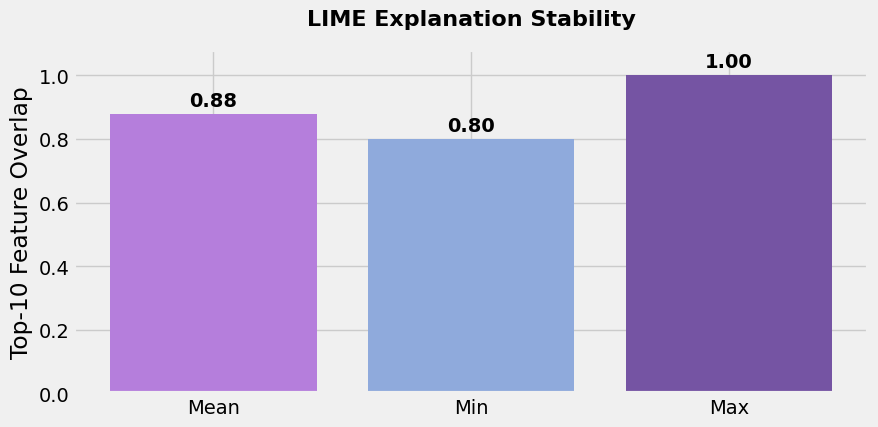

In [ ]:

from itertools import combinations
from lime.lime_tabular import LimeTabularExplainer
import numpy as np
import matplotlib.pyplot as plt

# Select the same recording and emotion as before
sample = X_shap.iloc[[0]]
class_idx = list(model.classes_).index('disgust')

# Repeat LIME with different random seeds
seeds = [11, 22, 33, 44, 55]
top_k = 10
lime_runs = []

for seed in seeds:
    explainer_run = LimeTabularExplainer(
        training_data=X_train.to_numpy(),
        feature_names=FEATURE_COLS,
        class_names=list(model.classes_),
        mode='classification',
        discretize_continuous=True,
        random_state=seed
    )

    exp = explainer_run.explain_instance(
        data_row=sample.iloc[0].to_numpy(),
        predict_fn=lambda x: model.predict_proba(
            pd.DataFrame(x, columns=FEATURE_COLS)
        ),
        labels=[class_idx],
        num_features=top_k,
        num_samples=5000
    )

    top_features = {
        FEATURE_COLS[i]
        for i, weight in exp.as_map()[class_idx]
    }

    lime_runs.append(top_features)

# Calculate agreement between all pairs of runs
overlaps = [
    len(a & b) / top_k
    for a, b in combinations(lime_runs, 2)
]

mean_agreement = np.mean(overlaps)
min_agreement = np.min(overlaps)
max_agreement = np.max(overlaps)

print("Mean Top-10 Agreement:", round(mean_agreement, 3))
print("Min Agreement:", round(min_agreement, 3))
print("Max Agreement:", round(max_agreement, 3))

# Visualization
plt.style.use('fivethirtyeight')

fig, ax = plt.subplots(figsize=(9, 4.5))

values = [mean_agreement, min_agreement, max_agreement]

ax.bar(
    ['Mean', 'Min', 'Max'],
    values,
    color=['#B57EDC', '#8FAADC', '#7554A3']
)

ax.set_ylim(0, 1.08)
ax.set_ylabel('Top-10 Feature Overlap')
ax.set_title(
    'LIME Explanation Stability',
    fontsize=16,
    fontweight='bold',
    pad=18
)

for i, value in enumerate(values):
    ax.text(
        i, value + 0.025,
        f'{value:.2f}',
        ha='center',
        fontweight='bold'
    )

plt.tight_layout()
plt.show()


**Пояснення:**

Для оцінювання стабільності LIME повторюємо пояснення одного аудіозапису п'ять разів із різними випадковими станами.

Для кожного запуску визначаємо десять найважливіших ознак, після чого обчислюємо частку спільних ознак для всіх пар запусків.

Висока узгодженість свідчитиме про стабільність вибору важливих ознак для досліджуваного запису. Водночас цей експеримент не перевіряє стабільність напрямків і числових значень внесків та не дозволяє робити висновки для всієї валідаційної вибірки.

- Mean Agreement = 0.88 — у середньому 88% ознак із Top-10 збігалися між повторними запусками LIME.
- Min = 0.80 — щонайменше 8 із 10.
- Max = 1.00 — іноді всі 10 збігалися.
Тобто для цього конкретного аудіозапису LIME показав досить стабільний вибір важливих ознак. Але стабільність самих ваг ми ще не перевіряли.

## 11. Conclusions and Limitations

### Conclusions

У цьому дослідженні було проаналізовано пояснюваність моделі Extra Trees для класифікації восьми емоцій за акустичними характеристиками голосу з використанням методів SHAP та LIME.

**Основні результати:**

1. Після підбору гіперпараметрів модель досягла Validation Accuracy = 0.447 та Macro F1 = 0.434, що перевищує показники початкової конфігурації.

2. Глобальний SHAP-аналіз показав, що серед найбільш впливових ознак моделі — `mfcc_01_mean`, `rms_std`, `rms_mean`, `spectral_rolloff_std` та `voiced_ratio`.

3. Локальні пояснення SHAP і LIME для правильно класифікованого запису `disgust` мали 8 спільних ознак серед десяти найважливіших, хоча порядок їхньої важливості відрізнявся.

4. SHAP Dependence Plot продемонстрував нелінійну залежність внеску `mfcc_01_mean` у прогнозовану ймовірність `disgust` від значення цієї ознаки.

5. Додатковий аналіз неправильно класифікованого запису дозволив порівняти внески ознак у ймовірності справжнього та помилково передбаченого класів.

6. Повторні запуски LIME використано для оцінювання стабільності вибору найважливіших ознак. Середня узгодженість Top-10 становила **[вставити результат]**.

### Limitations

- Якість моделі залишається обмеженою, тому пояснення потрібно інтерпретувати з урахуванням значної кількості помилок класифікації.
- Глобальний SHAP-аналіз виконано на вибірці зі 100 валідаційних записів, тому отримані результати можуть залежати від складу вибірки.
- Локальне порівняння SHAP і LIME виконано для окремого аудіозапису й не доводить узгодженості методів для всіх записів.
- LIME використовує штучно змінені приклади, які можуть не повністю відповідати реалістичним комбінаціям акустичних характеристик.
- SHAP і LIME пояснюють поведінку моделі, але не встановлюють причинно-наслідкові зв'язки між характеристиками голосу та емоціями людини.

### Final Takeaway

SHAP і LIME доповнюють традиційні метрики якості класифікації, дозволяючи досліджувати внески акустичних характеристик у передбачення моделі. Їхнє спільне використання допомагає аналізувати як загальні закономірності поведінки класифікатора, так і окремі правильні та неправильні передбачення.